## Asset Class Galaxy


### Settings


In [1]:
# Set refresh_timeseries=True to download timeseries. Otherwise symbol-cache is used.
refresh_timeseries = False
throttle_limit = 100
wait_time = 30


In [2]:
%%javascript
IPython.OutputArea.prototype._should_scroll = function(lines) {
    return false;
}


<IPython.core.display.Javascript object>

### Build asset-classes.csv


AGG 

AOA 

AOK 

AOM 

AOR 

...

XLP 

XLRE 

XLU 

XLV 

XLY 

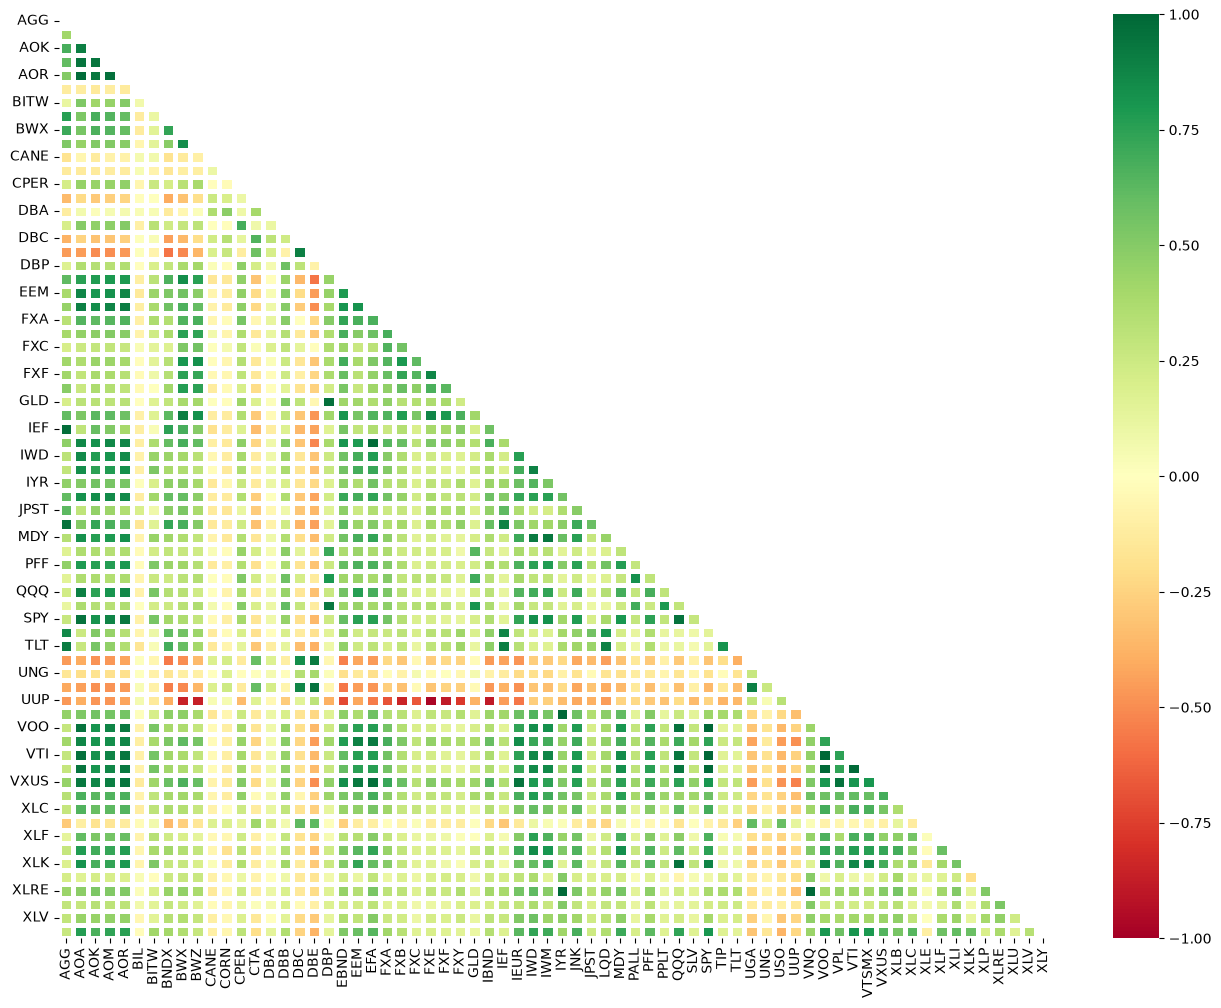

In [3]:
from pathlib import Path

import pandas as pd

import brownbear as bb

bb.notebook_display_options()

directory = Path('.')

# asset2etf maps each asset class to a representative ETF.
asset2etf = pd.read_csv('asset-classes-2-etf.csv', skip_blank_lines=True, comment='#')
asset2etf = asset2etf.set_index(['Asset Class'])['ETF'].to_dict()
symbols = sorted(set(asset2etf.values()))

bb.fetch_timeseries(symbols, refresh=refresh_timeseries, throttle_limit=throttle_limit, wait_time=wait_time)
bb.compile_timeseries(symbols, output_path=directory / 'symbols-timeseries.csv')

df = pd.read_csv('symbols-timeseries.csv', skip_blank_lines=True, comment='#')
df.set_index("Date", inplace=True)

corr_map = bb.correlation_map(df, method='log', days=bb.TRADING_DAYS_PER_YEAR)

with open('asset-classes-in.csv') as f:
    lines = [line.strip() for line in f]

out = []
for line in lines:
    if not line or line.startswith('#'):
        out.append(line)
        continue
    fields = [field.strip() for field in line.split(',')]
    assetA = fields[0].strip('"')
    assetB = fields[1].strip('"')
    if assetA == assetB or assetA == 'Asset Class A':
        out.append(line)
        continue
    etfA = asset2etf[assetA]
    etfB = asset2etf[assetB]
    corrAB = corr_map.loc[etfA, etfB]
    out.append(f'"{assetA}","{assetB}","{corrAB:0.2f}"')

with open('asset-classes.csv', 'w') as f:
    for line in out:
        f.write(line + '\n')


### Build investment-options.csv


In [4]:
import numpy as np

metrics = bb.compute_investment_metrics(df)

with open('investment-options-in.csv') as f:
    out = [line.strip() for line in f]

for asset_class, symbol in asset2etf.items():
    ret_3mo = metrics['annual_returns_3mo'][symbol]
    ret_6mo = metrics['annual_returns_6mo'][symbol]
    ret_1yr = metrics['annual_returns_1yr'][symbol]
    ret_1_1yr = metrics['annual_returns_1_1yr'][symbol]
    ret_3yr = metrics['annual_returns_3yr'][symbol]
    ret_5yr = metrics['annual_returns_5yr'][symbol]
    if np.isnan(ret_3yr):
        ret_3yr = ret_1yr
    if np.isnan(ret_5yr):
        ret_5yr = ret_3yr
    vola = metrics['vola'][symbol] * 100
    ds_vola = metrics['ds_vola'][symbol] * 100
    sd_1yr = metrics['std_dev_1yr'][symbol] * 100
    sd_3yr = metrics['std_dev_3yr'][symbol] * 100
    sd_5yr = metrics['std_dev_5yr'][symbol] * 100
    out.append(
        f'"{asset_class}","{asset_class}","{asset_class}",'
        f'"{ret_3mo:0.2f}","{ret_6mo:0.2f}","{ret_1yr:0.2f}","{ret_1_1yr:0.2f}","{ret_3yr:0.2f}",'
        f'"{ret_5yr:0.2f}","{vola:0.2f}","{ds_vola:0.2f}","{sd_1yr:0.2f}","{sd_3yr:0.2f}","{sd_5yr:0.2f}"'
    )

with open('investment-options.csv', 'w') as f:
    for line in out:
        f.write(line + '\n')

investment_options = pd.read_csv('investment-options.csv', skip_blank_lines=True, comment='#')
investment_options


,Investment Option,Description,Asset Class,3 mo,6 mo,1 Yr,1-1 Yr,3 Yr,5 Yr,Vola,DS Vola,SD 1 Yr,SD 3 Yr,SD 5 Yr
0,US Stocks,US Stocks,US Stocks,47.86,27.16,30.22,29.16,23.38,13.08,10.22,5.11,12.36,13.59,16.01
1,Global Stocks,Global Stocks,Global Stocks,11.64,40.90,32.89,31.64,19.61,9.11,19.27,10.16,13.27,12.41,15.05
2,US Bonds,US Bonds,US Bonds,-5.25,0.45,5.68,5.42,4.12,0.24,4.58,2.80,3.10,5.50,6.40
3,Global Bonds,Global Bonds,Global Bonds,-4.35,0.81,2.44,2.33,4.36,0.51,5.28,3.26,3.04,4.10,5.31
4,Cash Equivalents,Cash Equivalents,Cash Equivalents,3.64,3.73,3.94,3.91,4.69,3.40,0.18,0.04,0.11,0.21,0.57
5,Real Estate,Real Estate,Real Estate,4.39,15.96,12.41,13.29,10.47,3.42,11.57,6.52,12.97,16.80,19.05
6,Commodities,Commodities,Commodities,90.29,83.09,44.08,44.77,13.85,13.30,22.10,14.00,17.69,14.51,15.91
7,Currencies,Currencies,Currencies,8.85,2.09,3.60,4.09,3.88,5.78,4.18,2.22,6.30,6.74,7.05
8,Managed Futures,Managed Futures,Managed Futures,-11.65,21.35,11.54,12.47,11.06,11.06,25.48,18.39,15.74,13.92,16.20
9,Balanced,Balanced,Balanced,8.98,12.38,15.46,14.94,11.43,5.07,7.44,4.00,6.08,7.12,8.90
